# El problema XOR y el perceptrón multicapa

La compuerta **XOR** (o exclusivo) vale 1 solo cuando las dos entradas son **diferentes**:

| $x_1$ | $x_2$ | XOR |
|:---:|:---:|:---:|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

En 1969 Minsky y Papert mostraron que un perceptrón de una sola neurona **no puede** aprender XOR. En esta libreta:

1. Comprobamos que el perceptrón simple falla.
2. Explicamos por qué.
3. Resolvemos XOR con un perceptrón **multicapa** (una capa oculta) entrenado con retropropagación.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
X = np.array([[0, 0],
              [0, 1],
              [1, 0],
              [1, 1]])
y = np.array([0, 1, 1, 0])

## 1. Intento con un perceptrón simple

Usamos exactamente la misma regla de aprendizaje que con AND y OR.

In [3]:
class Perceptron:
    def __init__(self, n_entradas, tasa_aprendizaje=0.1, epocas=100, semilla=1):
        rng = np.random.default_rng(semilla)
        self.w = rng.normal(0, 0.5, n_entradas)
        self.b = 0.0
        self.eta = tasa_aprendizaje
        self.epocas = epocas
        self.errores_por_epoca = []

    def suma_neta(self, X):
        return X @ self.w + self.b

    def predecir(self, X):
        return np.where(self.suma_neta(X) >= 0, 1, 0)

    def entrenar(self, X, y):
        for _ in range(self.epocas):
            errores = 0
            for xi, yi in zip(X, y):
                error = yi - self.predecir(xi)
                self.w += self.eta * error * xi
                self.b += self.eta * error
                errores += int(error != 0)
            self.errores_por_epoca.append(errores)
            if errores == 0:
                break
        return self

p = Perceptron(n_entradas=2, epocas=100).entrenar(X, y)
print("Errores en las últimas 10 épocas:", p.errores_por_epoca[-10:])
print("Predicciones:", p.predecir(X), " Esperado:", y)
print("Exactitud:", (p.predecir(X) == y).mean())

Errores en las últimas 10 épocas: [4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
Predicciones: [1 1 0 0]  Esperado: [0 1 1 0]
Exactitud: 0.5


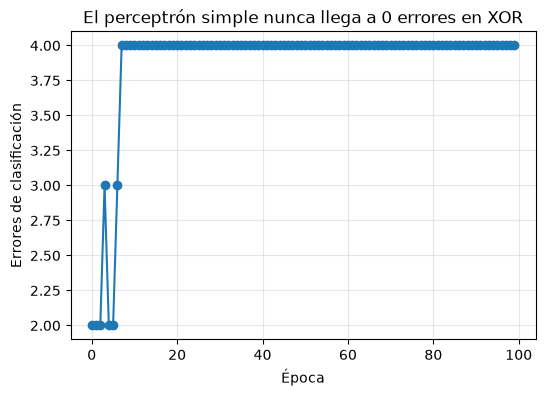

In [4]:
plt.figure(figsize=(6, 4))
plt.plot(p.errores_por_epoca, "o-")
plt.xlabel("Época"); plt.ylabel("Errores de clasificación")
plt.title("El perceptrón simple nunca llega a 0 errores en XOR")
plt.grid(alpha=0.3)
plt.show()

## 2. ¿Por qué falla?

Un perceptrón simple separa el plano con **una sola recta**. Los puntos de XOR están en las esquinas de un cuadrado:

- Clase 1: $(0,1)$ y $(1,0)$ (una diagonal)
- Clase 0: $(0,0)$ y $(1,1)$ (la otra diagonal)

No existe ninguna recta que deje las dos esquinas de la clase 1 de un lado y las dos de la clase 0 del otro. Se dice que XOR **no es linealmente separable**.

También se puede ver con álgebra. Con salida 1 cuando $w_1x_1 + w_2x_2 + b \ge 0$ se necesitaría:

- $(0,0)\to 0$: $b < 0$
- $(0,1)\to 1$: $w_2 + b \ge 0$
- $(1,0)\to 1$: $w_1 + b \ge 0$
- $(1,1)\to 0$: $w_1 + w_2 + b < 0$

Sumando las dos del medio: $w_1 + w_2 + 2b \ge 0$, o sea $w_1 + w_2 + b \ge -b > 0$, lo cual contradice la cuarta condición. **No hay solución.**

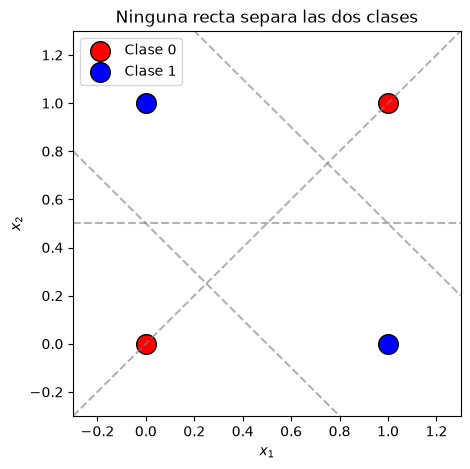

In [5]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(X[y == 0, 0], X[y == 0, 1], c="red", s=200, edgecolors="k", label="Clase 0")
ax.scatter(X[y == 1, 0], X[y == 1, 1], c="blue", s=200, edgecolors="k", label="Clase 1")
xs = np.linspace(-0.3, 1.3, 10)
for m, c in [(-1, 0.5), (-1, 1.5), (0, 0.5), (1, 0)]:
    ax.plot(xs, m * xs + c, "--", color="gray", alpha=0.6)
ax.set_xlim(-0.3, 1.3); ax.set_ylim(-0.3, 1.3)
ax.set_title("Ninguna recta separa las dos clases")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.legend()
plt.show()

## 3. La solución: una capa oculta

Si combinamos varias neuronas, la red puede formar fronteras no lineales. XOR se puede expresar con compuertas que sí son linealmente separables:

$$x_1 \oplus x_2 = (x_1 \lor x_2) \land \lnot(x_1 \land x_2) = \text{OR} \;\land\; \text{NAND}$$

Por lo tanto una red con **2 neuronas ocultas** (una hace OR y la otra NAND) y una neurona de salida (que hace AND) resuelve el problema. La capa oculta **transforma el espacio** de entrada a uno donde las clases sí son separables por una recta.

### Primero, con pesos hechos a mano
Para comprobar la idea, asignamos los pesos manualmente.

In [6]:
def escalon(z):
    return (z >= 0).astype(int)

# Capa oculta: neurona 1 = OR, neurona 2 = NAND
W1 = np.array([[ 1.0, -1.0],
               [ 1.0, -1.0]])      # (entradas x neuronas ocultas)
b1 = np.array([-0.5, 1.5])

# Capa de salida: AND de las dos neuronas ocultas
W2 = np.array([1.0, 1.0])
b2 = -1.5

H = escalon(X @ W1 + b1)
salida = escalon(H @ W2 + b2)

print("Salida de la capa oculta (OR, NAND):")
print(H)
print("Salida final:", salida, " Esperado:", y)

Salida de la capa oculta (OR, NAND):
[[0 1]
 [1 1]
 [1 1]
 [1 0]]
Salida final: [0 1 1 0]  Esperado: [0 1 1 0]


## 4. Ahora que la red aprenda sola

Entrenamos un perceptrón multicapa 2 → 4 → 1 con **retropropagación (backpropagation)**. Como el escalón no es derivable, usamos la función **sigmoide**:

$$\sigma(z) = \frac{1}{1 + e^{-z}}, \qquad \sigma'(z) = \sigma(z)\,(1 - \sigma(z))$$

**Propagación hacia adelante**

$$h = \sigma(XW_1 + b_1), \qquad \hat{y} = \sigma(hW_2 + b_2)$$

**Función de pérdida** (error cuadrático medio): $L = \frac{1}{N}\sum (\hat{y} - y)^2$

**Retropropagación**: aplicamos la regla de la cadena de la salida hacia la entrada

$$\delta_2 = (\hat{y} - y)\,\hat{y}(1-\hat{y}), \qquad \delta_1 = (\delta_2 W_2^T)\, h(1-h)$$

y actualizamos con descenso del gradiente: $W \leftarrow W - \eta\, \nabla_W L$.

In [7]:
def sigmoide(z):
    return 1 / (1 + np.exp(-z))

class RedXOR:
    def __init__(self, n_ocultas=4, tasa_aprendizaje=1.0, semilla=0):
        rng = np.random.default_rng(semilla)
        self.W1 = rng.normal(0, 1, (2, n_ocultas))
        self.b1 = np.zeros(n_ocultas)
        self.W2 = rng.normal(0, 1, (n_ocultas, 1))
        self.b2 = np.zeros(1)
        self.eta = tasa_aprendizaje
        self.perdidas = []

    def adelante(self, X):
        self.h = sigmoide(X @ self.W1 + self.b1)
        self.y_hat = sigmoide(self.h @ self.W2 + self.b2)
        return self.y_hat

    def entrenar(self, X, y, epocas=5000):
        y = y.reshape(-1, 1)
        for _ in range(epocas):
            y_hat = self.adelante(X)
            self.perdidas.append(np.mean((y_hat - y) ** 2))

            # retropropagación
            d2 = (y_hat - y) * y_hat * (1 - y_hat)
            d1 = (d2 @ self.W2.T) * self.h * (1 - self.h)

            self.W2 -= self.eta * self.h.T @ d2
            self.b2 -= self.eta * d2.sum(axis=0)
            self.W1 -= self.eta * X.T @ d1
            self.b1 -= self.eta * d1.sum(axis=0)
        return self

    def predecir(self, X):
        return (self.adelante(X) >= 0.5).astype(int).ravel()

red = RedXOR().entrenar(X, y, epocas=5000)

print("Pérdida final:", red.perdidas[-1])
print("Probabilidades:", red.adelante(X).ravel().round(3))
print("Predicciones:  ", red.predecir(X), " Esperado:", y)

Pérdida final: 0.0003404861582191678
Probabilidades: [0.007 0.981 0.981 0.024]
Predicciones:   [0 1 1 0]  Esperado: [0 1 1 0]


## 5. Curva de aprendizaje

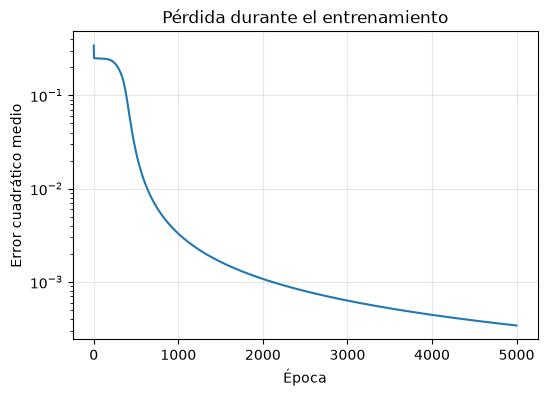

In [8]:
plt.figure(figsize=(6, 4))
plt.plot(red.perdidas)
plt.xlabel("Época"); plt.ylabel("Error cuadrático medio")
plt.title("Pérdida durante el entrenamiento")
plt.yscale("log"); plt.grid(alpha=0.3)
plt.show()

## 6. Frontera de decisión de la red

Ahora la frontera ya **no es una recta**: la capa oculta la dobla para encerrar correctamente las dos diagonales.

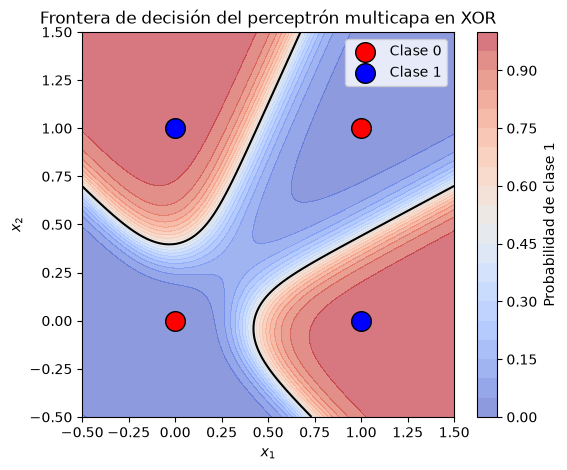

In [9]:
xx, yy = np.meshgrid(np.linspace(-0.5, 1.5, 200), np.linspace(-0.5, 1.5, 200))
malla = np.c_[xx.ravel(), yy.ravel()]
zz = red.adelante(malla).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(6, 5))
c = ax.contourf(xx, yy, zz, levels=20, cmap="coolwarm", alpha=0.6)
ax.contour(xx, yy, zz, levels=[0.5], colors="k")
ax.scatter(X[y == 0, 0], X[y == 0, 1], c="red", s=200, edgecolors="k", label="Clase 0")
ax.scatter(X[y == 1, 0], X[y == 1, 1], c="blue", s=200, edgecolors="k", label="Clase 1")
plt.colorbar(c, label="Probabilidad de clase 1")
ax.set_title("Frontera de decisión del perceptrón multicapa en XOR")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.legend(loc="upper right")
plt.show()

## 7. Lo que aprendió la capa oculta

Veamos las entradas después de pasar por la capa oculta. En ese nuevo espacio, los puntos de ambas clases **sí** se pueden separar con una recta, y por eso la neurona de salida logra clasificarlos.

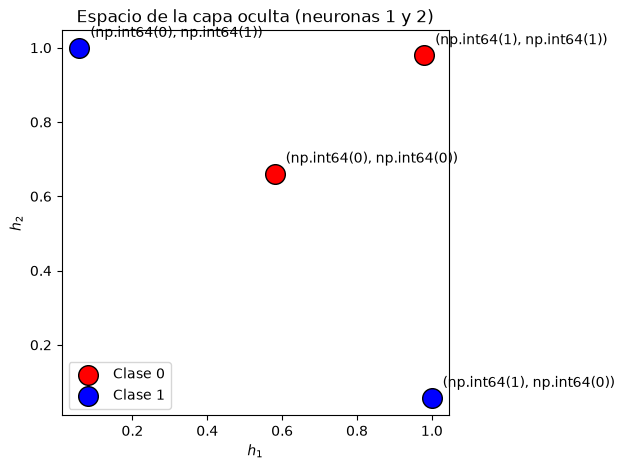

In [10]:
red.adelante(X)
H = red.h

# proyección a 2 dimensiones con las dos primeras neuronas ocultas
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(H[y == 0, 0], H[y == 0, 1], c="red", s=200, edgecolors="k", label="Clase 0")
ax.scatter(H[y == 1, 0], H[y == 1, 1], c="blue", s=200, edgecolors="k", label="Clase 1")
for xi, hi in zip(X, H):
    ax.annotate(str(tuple(xi)), (hi[0], hi[1]), textcoords="offset points", xytext=(8, 8))
ax.set_title("Espacio de la capa oculta (neuronas 1 y 2)")
ax.set_xlabel("$h_1$"); ax.set_ylabel("$h_2$"); ax.legend()
plt.show()

## 8. Conclusiones

- Un perceptrón simple solo resuelve problemas **linealmente separables** (AND, OR), pero **no** XOR.
- Añadir una **capa oculta** permite que la red aprenda representaciones intermedias y fronteras **no lineales**.
- Una función de activación **no lineal** (sigmoide, tanh, ReLU) es indispensable: sin ella, varias capas equivaldrían a una sola capa lineal.
- La **retropropagación** calcula cómo cambiar cada peso usando la regla de la cadena, y el descenso del gradiente los ajusta.
- Este es el principio de las redes neuronales profundas: apilar capas para resolver problemas cada vez más complejos.